# Organizando la gira de Los Auténticos Descendentes

Inteligencia Artificial - Facundo A. Lucianna - CEIA - FIUBA

**Los Auténticos Descendentes** presentan su nuevo disco, **«After Annealing»**, y salen a recorrer el país con la **Gira Mínimo Global**. El presupuesto es ajustado, así que la banda viaja en una avioneta clandestina que no usa rutas: va en línea recta de una ciudad a la siguiente.

El manager tiene que decidir en qué orden visitar las ciudades. Hay dos condiciones que no se negocian: la gira arranca en **Buenos Aires**, donde se presenta el disco, y termina en la **Base Marambio**, en la Antártida, donde la banda cierra con un show para la dotación de la base. Lo que queda por decidir es el orden del resto de las ciudades, y queremos el que haga recorrer la menor cantidad de kilómetros.

Este es el **problema del viajante** (*Travelling Salesman Problem* o TSP), uno de los problemas de optimización más estudiados. En su versión clásica el viajante vuelve a la ciudad de donde partió. En la nuestra no vuelve, porque los extremos están fijos, pero eso no cambia la dificultad: sigue siendo un problema NP-difícil, es decir, no se conoce ningún algoritmo que encuentre la gira óptima en un tiempo razonable a medida que crece la cantidad de ciudades. Por eso es un buen candidato para los algoritmos de búsqueda local, que no garantizan encontrar el óptimo pero sí encuentran buenas soluciones en poco tiempo.

La gira tiene dos versiones, según el presupuesto que consiga el manager:

- **Gira Federal**: las 24 capitales más la Base Marambio.
- **Gira Pueblo por Pueblo**: 111 lugares, las capitales y todas las ciudades de más de 30.000 habitantes.

En esta notebook vamos a modelar el problema: definir qué es un estado, cuál es la función de costo y quiénes son los vecinos. En las siguientes notebooks usaremos estas herramientas con distintos algoritmos de búsqueda local.

> 🧠 **Nota**: Todas las funciones que usamos están en el archivo `gira.py`, que está comentado en detalle. El origen de los datos y sus licencias se describen en `datos/DATOS.md`.

In [1]:
import math
import random

import gira

random.seed(42)

---

## Las ciudades

Las ciudades de cada gira se cargan con la función `load_cities()`, que devuelve un `DataFrame` de pandas. Empecemos por la Gira Federal:

In [2]:
capitals = gira.load_cities("capitales")
capitals

,nombre,provincia,latitud,longitud,poblacion,capital
0,Resistencia,Chaco,-27.46363,-58.98665,290793,True
1,Posadas,Misiones,-27.39184,-55.92379,305874,True
2,La Plata,Buenos Aires,-34.92126,-57.95442,195443,True
3,Formosa,Formosa,-26.18489,-58.17313,222226,True
4,Corrientes,Corrientes,-27.46784,-58.83440,346334,True
5,Buenos Aires,Ciudad Autónoma de Buenos Aires,-34.61315,-58.37723,2891082,True
6,Viedma,Río Negro,-40.81519,-63.00040,48940,True
7,Ushuaia,"Tierra del Fuego, Antártida e Islas del Atlánt...",-54.81084,-68.31591,56825,True
8,Santiago del Estero,Santiago del Estero,-27.80047,-64.26285,252192,True
9,Santa Rosa,La Pampa,-36.61617,-64.28991,102860,True


El índice del `DataFrame`, que va de 0 a 24, es el número con el que vamos a identificar a cada ciudad de aquí en adelante. Por ejemplo, la ciudad `0` es Resistencia.

La Gira Pueblo por Pueblo se carga de la misma forma:

In [3]:
cities = gira.load_cities("pueblo_por_pueblo")

print(f"La Gira Pueblo por Pueblo tiene {len(cities)} lugares")
cities.sample(5, random_state=42)

La Gira Pueblo por Pueblo tiene 111 lugares


,nombre,provincia,latitud,longitud,poblacion,capital
78,Trenque Lauquen,Buenos Aires,-35.97334,-62.73275,39975,False
10,Santa Fe,Santa Fe,-31.64881,-60.70868,391164,True
4,Corrientes,Corrientes,-27.46784,-58.83440,346334,True
84,General Güemes,Salta,-24.67445,-65.04660,38048,False
64,Río Tercero,Córdoba,-32.17675,-64.11295,53389,False


---

## Distancias

Como la banda viaja en avioneta, la distancia entre dos ciudades es la distancia en línea recta. Pero no es una recta sobre un plano, porque la Tierra es (más o menos) una esfera. La distancia entre dos puntos sobre una esfera se calcula con la **fórmula de haversine**, a partir de la latitud $\varphi$ y la longitud $\lambda$ de cada ciudad:

$$d = 2R \arcsin\left(\sqrt{\sin^2\left(\frac{\varphi_2 - \varphi_1}{2}\right) + \cos\varphi_1 \cos\varphi_2 \sin^2\left(\frac{\lambda_2 - \lambda_1}{2}\right)}\right)$$

donde $R = 6371$ km es el radio de la Tierra.

Los algoritmos de búsqueda van a necesitar estas distancias millones de veces, así que las calculamos una sola vez para todos los pares de ciudades con la función `distance_matrix()`. El resultado es una matriz donde el elemento `[i, j]` es la distancia en km entre la ciudad `i` y la ciudad `j`:

In [4]:
distances = gira.distance_matrix(capitals)

print(f"Tamaño de la matriz: {distances.shape}")

Tamaño de la matriz: (25, 25)


Veamos algunas distancias. Para que sea más fácil, armamos una pequeña función que busca las ciudades por nombre:

In [5]:
names = capitals["nombre"].tolist()


def km_between(city_a, city_b):
    km = distances[names.index(city_a), names.index(city_b)]
    return gira.format_km(km)


print("Buenos Aires - Córdoba:", km_between("Buenos Aires", "Córdoba"))
print("Buenos Aires - Ushuaia:", km_between("Buenos Aires", "Ushuaia"))
print("Ushuaia - Base Marambio:", km_between("Ushuaia", "Base Marambio"))

Buenos Aires - Córdoba: 648 km
Buenos Aires - Ushuaia: 2.374 km
Ushuaia - Base Marambio: 1.234 km


---

## Modelando el problema para búsqueda local

A diferencia de los problemas de la clase anterior, acá no buscamos una secuencia de acciones que nos lleve a un estado objetivo. Cada estado ya es una gira completa, y lo que buscamos es la gira con el menor costo. Para aplicar búsqueda local necesitamos definir tres cosas:

- **Estado**: cómo representamos una gira.
- **Función de costo**: cuánto cuesta una gira.
- **Vecinos**: a qué giras podemos movernos desde una gira dada.

Ninguna de estas definiciones es única, y la forma en que las elijamos va a tener mucho impacto en qué tan bien funcionan los algoritmos.

### Estado

Una primera idea sería representar la gira como una lista de 25 fechas, donde en cada fecha la banda toca en cualquiera de las 25 ciudades. Es fácil de implementar, pero la mayoría de los estados no serían giras válidas: habría ciudades repetidas, ciudades que nunca se visitan y giras que no arrancan en Buenos Aires. Tendríamos que penalizar esos casos en la función de costo, y el algoritmo perdería la mayor parte del tiempo recorriendo estados que no sirven.

Si estudiamos un poco el problema, vemos que una gira válida es simplemente un **orden** de las ciudades, en el que cada una aparece una única vez. Es decir, una permutación. Si además dejamos fijas la primera posición (Buenos Aires) y la última (Base Marambio), cualquier permutación de las ciudades del medio es una gira válida. Las restricciones del problema quedan dentro de la representación del estado, y no hace falta controlarlas después.

Veamos cuánto achica esto el espacio de búsqueda. Con $n$ ciudades, la primera idea tiene $n^n$ estados, mientras que con la permutación de extremos fijos quedan $(n-2)!$:

In [6]:
for instance in gira.INSTANCES:
    n = len(gira.load_cities(instance))
    print(f"{instance} ({n} lugares)")
    print(f"    Primera idea:            {float(n**n):.1e} estados")
    print(f"    Permutación con extremos: {float(math.factorial(n - 2)):.1e} estados")

capitales (25 lugares)
    Primera idea:            8.9e+34 estados
    Permutación con extremos: 2.6e+22 estados
pueblo_por_pueblo (111 lugares)
    Primera idea:            1.1e+227 estados
    Permutación con extremos: 1.4e+176 estados


Aunque el espacio sigue siendo enorme, lo redujimos en muchos órdenes de magnitud sin hacer nada más que entender el problema. Para tener una idea, si pudiéramos evaluar mil millones de giras por segundo, recorrer todas las giras de la Gira Federal llevaría más de 800.000 años.

En el código, una gira es una lista con los índices de las ciudades en el orden en que se visitan. La función `init_state()` genera una gira al azar: arranca en Buenos Aires, termina en la Base Marambio y mezcla el resto.

In [7]:
tour = gira.init_state(capitals)

print("Gira:", tour)
print("Primera fecha:", capitals.loc[tour[0], "nombre"])
print("Última fecha:", capitals.loc[tour[-1], "nombre"])

Gira: [5, 17, 16, 2, 15, 6, 14, 18, 13, 23, 7, 10, 1, 20, 12, 11, 22, 4, 19, 8, 9, 0, 3, 21, 24]
Primera fecha: Buenos Aires
Última fecha: Base Marambio


Con la función `plot_tour()` podemos ver la gira sobre el mapa. Buenos Aires se marca con ■, la Base Marambio con ▼ y las capitales con ★:

> 🗺️ **Nota**: La celda de abajo genera un mapa interactivo, donde se puede hacer zoom y ver el nombre y la fecha de cada ciudad al pasar el mouse. La dejamos sin ejecutar para que la notebook sea liviana. Si querés verlo, ejecutala. Debajo está la versión estática del mismo mapa.

In [ ]:
gira.plot_tour(capitals, tour, distances, title="Gira al azar", interactive=True)

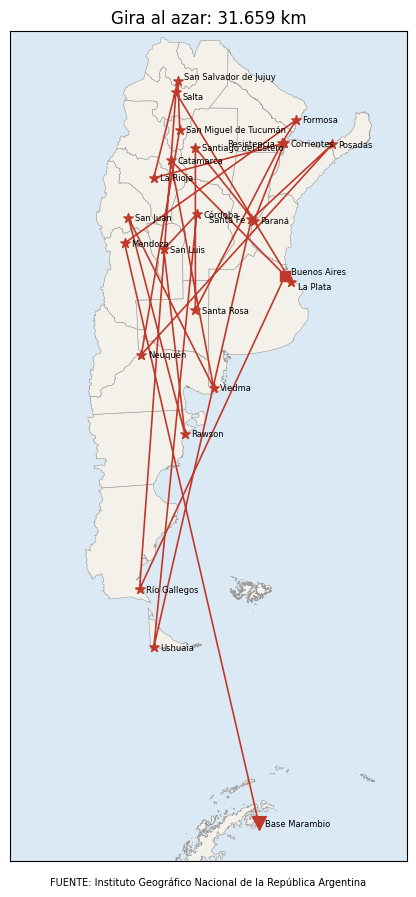

In [8]:
gira.plot_tour(capitals, tour, distances, title="Gira al azar")

Como era de esperar, una gira al azar es un desastre: la avioneta va y viene de una punta a la otra del país.

### Función de costo

La función de costo es la suma de los kilómetros de cada tramo de la gira. Se calcula con `cost_function()`:

In [9]:
print("Costo de la gira al azar:", gira.format_km(gira.cost_function(tour, distances)))

Costo de la gira al azar: 31.659 km


### Vecinos

Nos falta definir a qué giras podemos movernos desde una gira dada. La idea más directa es **intercambiar dos ciudades** de lugar: si Salta tocaba en la fecha 3 y Córdoba en la fecha 8, en la gira vecina Salta pasa a la fecha 8 y Córdoba a la 3. Funciona, pero no aprovecha nada de lo que sabemos del problema.

Y hay algo que sí sabemos: **en una buena gira, los tramos de la avioneta nunca se cruzan**. Si dos tramos se cruzan, siempre se pueden reconectar de otra forma para que no se crucen, y la gira queda más corta. Veámoslo con cuatro ciudades. La gira `A → C → B → D` tiene dos tramos que se cruzan, `A → C` y `B → D`:

```text
  B ←──────── C
    ╲       ↗
      ╲   ╱
        ╳
      ╱   ╲
    ╱       ↘
  A           D
```

Si cortamos esos dos tramos y volvemos a unir las ciudades del otro lado, con `A → B` y `C → D`, el cruce desaparece:

```text
  B ────────→ C
  ↑           │
  │           ↓
  A           D
```

Como lista, la gira pasó de `[A, C, B, D]` a `[A, B, C, D]`: el bloque que estaba entre los dos tramos cortados quedó **invertido**. Esto vale en general: cortar dos tramos y reconectarlos del otro lado es lo mismo que dar vuelta todo lo que hay entre ellos. Este movimiento se llama **2-opt**, por los dos tramos que se cortan, y es el que vamos a usar para definir los vecinos.

Un movimiento 2-opt se identifica con dos posiciones `(i, j)`, y consiste en invertir el tramo de la gira que va de la posición `i` a la `j`. La función `two_opt()` aplica el movimiento y devuelve una nueva gira:

In [10]:
example = ["BA", "Salta", "Mendoza", "Neuquén", "Jujuy", "Ushuaia", "Marambio"]

print("Antes:  ", example)
print("Después:", gira.two_opt(example, 1, 4))

Antes:   ['BA', 'Salta', 'Mendoza', 'Neuquén', 'Jujuy', 'Ushuaia', 'Marambio']
Después: ['BA', 'Jujuy', 'Neuquén', 'Mendoza', 'Salta', 'Ushuaia', 'Marambio']


Notá que las posiciones `0` y `6` no se tocan nunca, así que la gira sigue arrancando en Buenos Aires y terminando en la Base Marambio.

#### El cruce del manager

Veamos un caso concreto. El manager armó la Gira Federal a mano, mirando el mapa:

In [11]:
manager_names = [
    "Buenos Aires", "La Plata", "Paraná", "Santa Fe", "Corrientes", "Resistencia",
    "Posadas", "Formosa", "Santiago del Estero", "San Miguel de Tucumán",
    "San Salvador de Jujuy", "Salta", "Catamarca", "La Rioja", "San Juan", "Mendoza",
    "San Luis", "Viedma", "Neuquén", "Santa Rosa", "Córdoba", "Rawson", "Río Gallegos",
    "Ushuaia", "Base Marambio",
]  # fmt: skip
manager_tour = [names.index(name) for name in manager_names]

print("Costo:", gira.format_km(gira.cost_function(manager_tour, distances)))

Costo: 10.206 km


> 🗺️ **Nota**: La celda de abajo genera un mapa interactivo, donde se puede hacer zoom y ver el nombre y la fecha de cada ciudad al pasar el mouse. La dejamos sin ejecutar para que la notebook sea liviana. Si querés verlo, ejecutala. Debajo está la versión estática del mismo mapa.

In [ ]:
gira.plot_tour(
    capitals, manager_tour, distances, title="Gira del manager", interactive=True
)

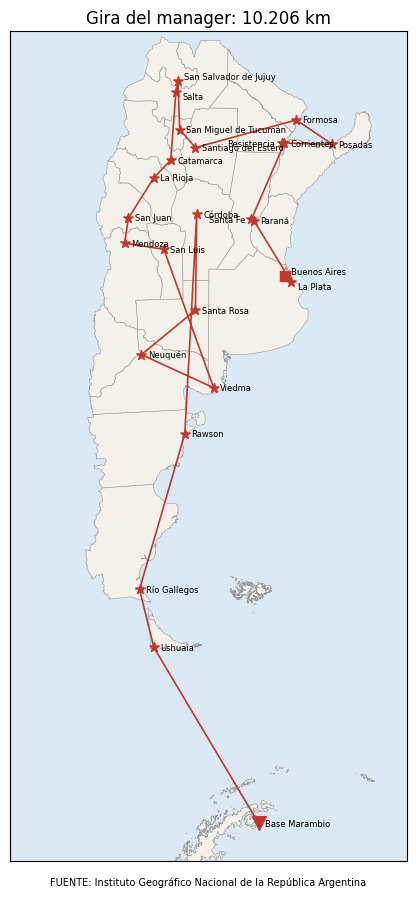

In [12]:
gira.plot_tour(capitals, manager_tour, distances, title="Gira del manager")

La gira va bastante bien hasta San Luis, pero ahí el manager se confundió: la avioneta baja hasta Viedma, sube a Neuquén, Santa Rosa y Córdoba, y vuelve a bajar hasta Rawson. Los tramos San Luis → Viedma y Córdoba → Rawson se cruzan.

Busquemos el mejor vecino de esta gira. La función `return_neib_states()` genera todas las giras vecinas, y nos quedamos con la de menor costo:

In [13]:
neighbors = gira.return_neib_states(manager_tour)
best_neighbor = min(neighbors, key=lambda t: gira.cost_function(t, distances))

print(f"Cantidad de vecinos: {len(neighbors)}")
best_km = gira.cost_function(best_neighbor, distances)
print("Costo del mejor vecino:", gira.format_km(best_km))
print("Gira del mejor vecino:", [names[k] for k in best_neighbor])

Cantidad de vecinos: 253
Costo del mejor vecino: 8.611 km
Gira del mejor vecino: ['Buenos Aires', 'La Plata', 'Paraná', 'Santa Fe', 'Corrientes', 'Resistencia', 'Posadas', 'Formosa', 'Santiago del Estero', 'San Miguel de Tucumán', 'San Salvador de Jujuy', 'Salta', 'Catamarca', 'La Rioja', 'San Juan', 'Mendoza', 'San Luis', 'Córdoba', 'Santa Rosa', 'Neuquén', 'Viedma', 'Rawson', 'Río Gallegos', 'Ushuaia', 'Base Marambio']


El mejor vecino invierte justamente el tramo Viedma, Neuquén, Santa Rosa, Córdoba, y con eso desaparece el cruce:

> 🗺️ **Nota**: La celda de abajo genera un mapa interactivo, donde se puede hacer zoom y ver el nombre y la fecha de cada ciudad al pasar el mouse. La dejamos sin ejecutar para que la notebook sea liviana. Si querés verlo, ejecutala. Debajo está la versión estática del mismo mapa.

In [ ]:
gira.plot_tours(
    capitals,
    {"Gira del manager": manager_tour, "Mejor vecino": best_neighbor},
    distances,
    interactive=True,
)

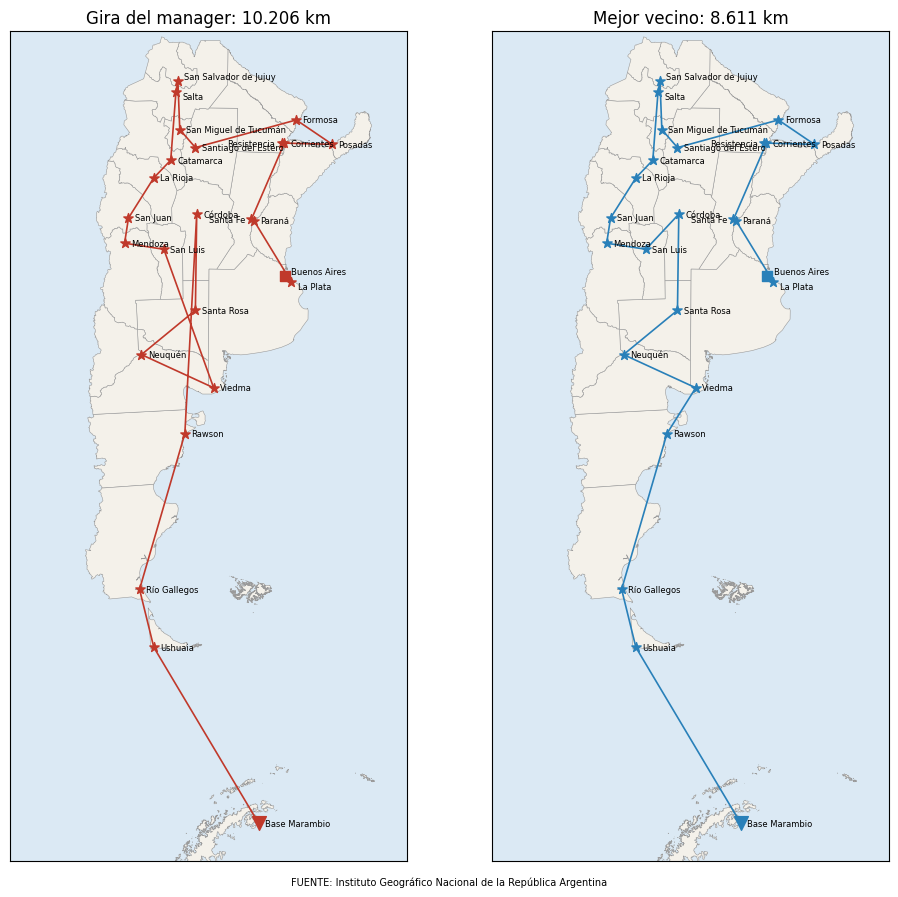

In [14]:
gira.plot_tours(
    capitals,
    {"Gira del manager": manager_tour, "Mejor vecino": best_neighbor},
    distances,
)

Con un único movimiento 2-opt deshicimos el cruce y ahorramos casi 1.600 km.

¿Qué hubiera pasado con el intercambio de dos ciudades? El mejor intercambio posible es cambiar Viedma por Córdoba. El cruce desaparece, pero las ciudades del medio quedan en el mismo orden que antes, que era el orden al revés: la avioneta iría de San Luis a Córdoba, Neuquén, Santa Rosa y Viedma, zigzagueando, y la gira quedaría en 8.942 km. Hace falta un segundo intercambio, Neuquén por Santa Rosa, para llegar a la gira que logra un único 2-opt. Acá son solo dos pasos, pero cuanto más largo es el bloque que hay que dar vuelta, más intercambios se necesitan, y alcanza con que uno de ellos empeore la gira para que un algoritmo que solo acepta mejoras se quede trabado. Esto es lo que nos da 2-opt: como aprovecha lo que sabemos del problema, cada movimiento tiene más sentido.

> 🧠 **Nota**: La gira del manager, aun sin el cruce, no es la mejor posible. En las próximas notebooks vamos a ver hasta dónde pueden mejorarla los algoritmos.

#### ¿Cuántos vecinos tiene una gira?

Un movimiento es cualquier par de posiciones `(i, j)` con $1 \le i < j \le n-2$, así que hay $\binom{n-2}{2}$ vecinos. La función `obtain_moves()` los lista:

In [15]:
for instance in gira.INSTANCES:
    n = len(gira.load_cities(instance))
    print(f"{instance}: {len(gira.obtain_moves(n))} vecinos por gira")

capitales: 253 vecinos por gira
pueblo_por_pueblo: 5886 vecinos por gira


Algunos algoritmos, como Simulated Annealing, no necesitan todos los vecinos sino uno elegido al azar. Para eso está la función `random_neib_state()`:

In [16]:
random_neighbor = gira.random_neib_state(manager_tour)

random_km = gira.cost_function(random_neighbor, distances)
print("Costo del vecino al azar:", gira.format_km(random_km))

Costo del vecino al azar: 12.659 km


### Calculando el costo de un vecino sin armarlo

Para encontrar el mejor vecino armamos las 253 giras vecinas y calculamos el costo de cada una, recorriéndola completa. En la Gira Pueblo por Pueblo serían 5.886 giras de 111 ciudades en cada paso del algoritmo, lo que se vuelve lento.

Pero si miramos qué hace un movimiento 2-opt, vemos que los tramos internos del bloque invertido se recorren igual, solo que al revés, y en avioneta la distancia de ida es la misma que la de vuelta. **Los únicos tramos que cambian son los dos de los bordes**:

```text
antes:    ... a → b ... c → d ...
después:  ... a → c ... b → d ...
```

Entonces la diferencia de costo entre la gira vecina y la actual es:

$$\Delta = d(a, c) + d(b, d) - d(a, b) - d(c, d)$$

Esto es lo que calcula la función `delta_cost()`, sin necesidad de armar la gira vecina. Si $\Delta$ es negativo, el movimiento acorta la gira. Verifiquemos que da lo mismo que calcular la diferencia recorriendo las giras completas:

In [17]:
i, j = 17, 20

new_tour = gira.two_opt(manager_tour, i, j)
full_difference = gira.cost_function(new_tour, distances) - gira.cost_function(
    manager_tour, distances
)
delta = gira.delta_cost(manager_tour, i, j, distances)

print(f"Recorriendo las giras completas: {full_difference:.2f} km")
print(f"Con delta_cost():                {delta:.2f} km")

Recorriendo las giras completas: -1595.32 km
Con delta_cost():                -1595.32 km


Calcular `delta_cost()` requiere siempre cuatro consultas a la matriz de distancias, sin importar cuántas ciudades tenga la gira. Esto va a ser clave para que los algoritmos puedan explorar muchas giras en poco tiempo.

---

## Resumen

Estas son las herramientas que vamos a usar en las próximas notebooks:

| Función | Qué hace |
|---|---|
| `load_cities(instance)` | Carga las ciudades de la Gira Federal (`"capitales"`) o de la Gira Pueblo por Pueblo (`"pueblo_por_pueblo"`) |
| `distance_matrix(cities)` | Calcula la matriz de distancias entre todas las ciudades |
| `init_state(cities)` | Genera una gira al azar, de Buenos Aires a la Base Marambio |
| `cost_function(tour, distances)` | Calcula los km totales de una gira |
| `obtain_moves(n)` | Lista todos los movimientos 2-opt `(i, j)` |
| `two_opt(tour, i, j)` | Aplica un movimiento 2-opt |
| `delta_cost(tour, i, j, distances)` | Calcula cuánto cambia el costo con un movimiento 2-opt, sin aplicarlo |
| `return_neib_states(tour)` | Genera todas las giras vecinas |
| `random_move(n)` | Elige un movimiento 2-opt al azar |
| `random_neib_state(tour)` | Genera una gira vecina al azar |
| `plot_tour(...)`, `plot_tours(...)` | Dibujan una o varias giras sobre el mapa |

En la próxima notebook vamos a usar estas herramientas para buscar la mejor gira con gradiente descendente.